# Data exploration

Exploration in the data so we can better understand the dataset. Also used to create the dataset to train models do answer Q1.

### Load the data and first cleaning

In [140]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def read_and_clean(path):
    df = pd.read_csv(path, dtype=str, skipinitialspace=True)
    df.columns = df.columns.str.strip()
    for c in df.columns:
        df[c] = df[c].str.strip()
    return df.replace("", np.nan)

#first clean the data
df_teams = read_and_clean("hockey_development_data/Teams.csv").query("lgID == 'NHL'").astype({'year': int})
df_scoring = read_and_clean("hockey_development_data/Scoring.csv").query("lgID == 'NHL'").astype({'year': int})
df_goalies = read_and_clean("hockey_development_data/Goalies.csv").query("lgID == 'NHL'").astype({'year': int})
df_coaches = read_and_clean("hockey_development_data/Coaches.csv").query("lgID == 'NHL'").astype({'year': int})

## Data Understanding 
Apply some methods so we can understand the distribution and relation in the data

In [141]:
sns.set_theme(style = "whitegrid")

print("Data distribution")

df_teams['GF_num'] = pd.to_numeric(df_teams['GF'], errors = 'coerce')
df_teams['GA_num'] = pd.to_numeric(df_teams['GA'], errors = 'coerce')
df_teams['Pts_num'] = pd.to_numeric(df_teams['Pts'], errors = 'coerce')
df_teams['year_num'] = pd.to_numeric(df_teams['year'], errors = 'coerce')

display(df_teams[['GF_num', 'GA_num', 'Pts_num']].describe().round(2))


#Data, playoff and points 
print("\nPivot Table")
df_teams['decade'] = (df_teams['year_num'] // 10) * 10
pivot_3d = df_teams.pivot_table(values = 'Pts_num', index = 'decade', columns = 'playoff', aggfunc = 'mean')
display(pivot_3d.round(1))

Data distribution


,GF_num,GA_num,Pts_num
count,1265.00,1265.00,1265.00
mean,226.75,226.75,74.51
std,70.58,72.53,23.05
min,17.00,35.00,2.00
25%,189.00,184.00,58.00
50%,231.00,232.00,77.00
75%,277.00,278.00,92.00
max,446.00,446.00,132.00



Pivot Table


playoff,CF,CQF,CSF,DF,DSF,F,ND,NHLF,PRE,QF,SC,SF
decade,,,,,,,,,,,,
1910,NaN,NaN,NaN,NaN,NaN,NaN,20.0,25.0,NaN,NaN,32.0,NaN
1920,NaN,NaN,NaN,NaN,NaN,52.8,NaN,35.2,NaN,46.9,41.6,50.2
1930,NaN,NaN,NaN,NaN,NaN,54.0,NaN,NaN,NaN,48.2,56.1,53.3
1940,NaN,NaN,NaN,NaN,NaN,61.6,NaN,NaN,NaN,43.5,67.5,58.0
1950,NaN,NaN,NaN,NaN,NaN,75.5,NaN,NaN,NaN,NaN,91.4,73.2
1960,NaN,NaN,NaN,NaN,NaN,76.0,NaN,NaN,NaN,77.5,86.4,81.6
1970,NaN,NaN,NaN,NaN,NaN,107.9,NaN,NaN,78.2,88.1,115.5,99.2
1980,84.6,NaN,NaN,85.6,83.0,98.6,NaN,NaN,83.1,94.2,105.1,83.0
1990,93.4,84.9,85.3,96.7,87.2,87.8,NaN,NaN,NaN,NaN,95.9,NaN


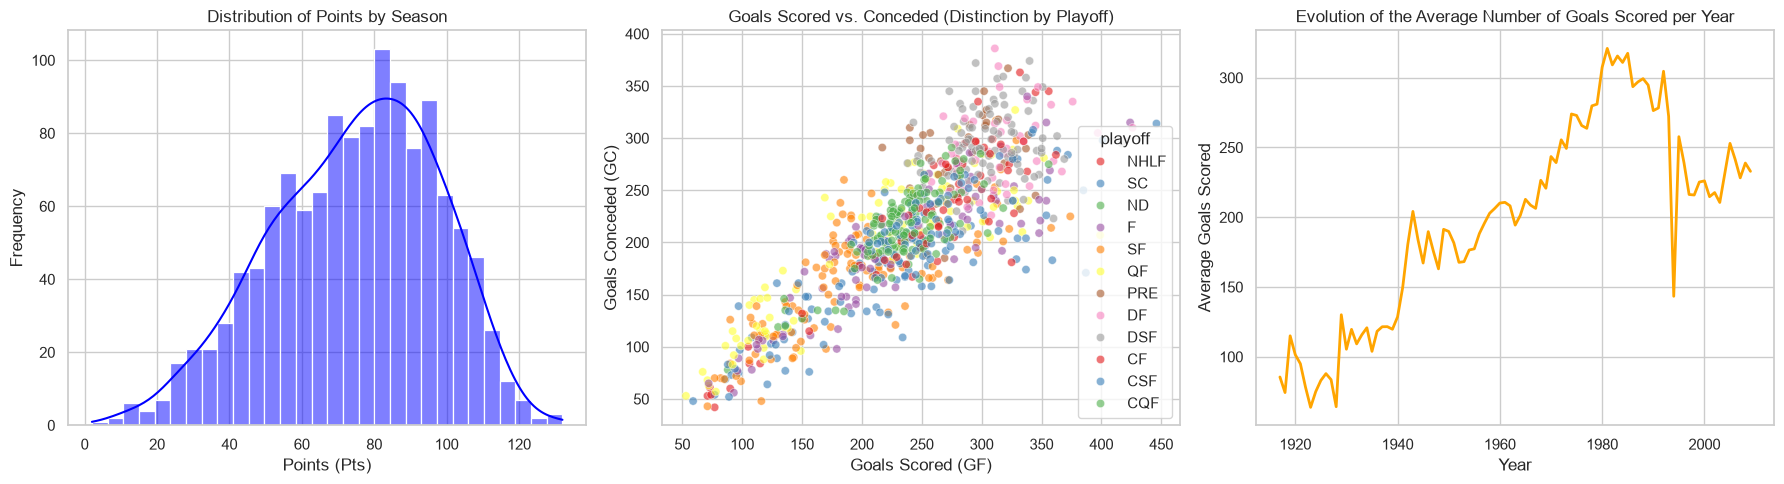

In [142]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#Points distribution
sns.histplot(df_teams['Pts_num'].dropna(), bins = 30, kde = True, ax = axes[0], color = 'blue')
axes[0].set_title('Distribution of Points by Season', fontsize=12)
axes[0].set_xlabel('Points (Pts)')
axes[0].set_ylabel('Frequency')

# goals scored and conceded
sns.scatterplot(data = df_teams, x = 'GF_num', y = 'GA_num', hue = 'playoff', palette = 'Set1', alpha = 0.6, ax = axes[1])
axes[1].set_title('Goals Scored vs. Conceded (Distinction by Playoff)', fontsize=12)
axes[1].set_xlabel('Goals Scored (GF)')
axes[1].set_ylabel('Goals Conceded (GC)')

# goals over the years
yearly_stats = df_teams.groupby('year_num')['GF_num'].mean().reset_index()
sns.lineplot(data = yearly_stats, x = 'year_num', y = 'GF_num', ax = axes[2], color = 'orange', linewidth = 2)
axes[2].set_title('Evolution of the Average Number of Goals Scored per Year', fontsize=12)
axes[2].set_xlabel('Year')
axes[2].set_ylabel('Average Goals Scored')

plt.tight_layout()
plt.show()

### Data Quality Tests 
Before processing the data, we test for null values, duplicates, logical rules of hockey, e.g., the number of wins cannot exceed the number of games played, and the range of years covered.

In [143]:
print("Nulls")
print(df_teams[['G', 'W', 'L', 'Pts']].isna().sum())

print(f"\nDuplicates")
print(f"Dup lines in table Teams: {df_teams.duplicated().sum()}")

# Consistency and Validity
df_teams[['G', 'W', 'L']] = df_teams[['G', 'W', 'L']].apply(pd.to_numeric, errors='coerce')
invalid_games = df_teams[df_teams['G'] < (df_teams['W'] + df_teams['L'])]
print(f"\nConsistency and Validity")
print(f"Cases where Wins + Losses exceed the number of games: {len(invalid_games)}")

print(f"\nThe data covers the periods of {df_teams['year'].min()} to {df_teams['year'].max()}")

Nulls
G      0
W      0
L      0
Pts    0
dtype: int64

Duplicates
Dup lines in table Teams: 0

Consistency and Validity
Cases where Wins + Losses exceed the number of games: 0

The data covers the periods of 1917 to 2009


### Aggregations and Z-Score

In [144]:
# aggregations
#score info
cols_scoring = ['G', 'A', 'Pts', 'PIM']
df_scoring[cols_scoring] = df_scoring[cols_scoring].apply(pd.to_numeric, errors = 'coerce')
teams_stats = df_scoring.groupby(['tmID', 'year'])[cols_scoring].sum(min_count = 1).reset_index()
teams_stats.rename(columns = {'G': 'teams_goals', 'Pts': 'teams_pts', 'PIM': 'teams_pim'}, inplace = True)

#goalies info
cols_goalies = ['SA', 'GA', 'Min']
df_goalies[cols_goalies] = df_goalies[cols_goalies].apply(pd.to_numeric, errors = 'coerce')
goalie_stats = df_goalies.groupby(['tmID', 'year'])[['SA', 'GA']].sum(min_count = 1).reset_index()
goalie_stats['team_save_pct'] = np.where(goalie_stats['SA'] > 0, 1 - (goalie_stats['GA'] / goalie_stats['SA']), np.nan)
goalie_stats.rename(columns = {'SA': 'team_SA', 'GA': 'team_GA'}, inplace = True)

#coach info
coach_stats = df_coaches.groupby(['tmID', 'year'])['coachID'].nunique().reset_index()
coach_stats.rename(columns = {'coachID': 'num_coaches'}, inplace = True)

# Fuse the data to df_final
df_final = df_teams.merge(teams_stats, on = ['tmID', 'year'], how = 'left')
df_final = df_final.merge(goalie_stats, on = ['tmID', 'year'], how = 'left')
df_final = df_final.merge(coach_stats, on = ['tmID', 'year'], how = 'left')

# convert the main statistics to numerical val
cols_team_num = ['G', 'W', 'L', 'T', 'OTL', 'Pts', 'GF', 'GA', 'rank']
for col in cols_team_num:
    if col in df_final.columns:
        df_final[col] = pd.to_numeric(df_final[col], errors = 'coerce')

df_final['G'] = df_final['G'].replace(0, np.nan)

# info about the games before we normalize it 
df_final['win_pct'] = df_final['W'] / df_final['G']
df_final['league_pts_per_game'] = df_final['Pts'] / df_final['G'] 
df_final['goal_diff_per_game'] = (df_final['GF'] - df_final['GA']) / df_final['G'] 
df_final['player_pts_per_game'] = df_final['teams_pts'] / df_final['G'] 
df_final['player_goals_per_game'] = df_final['teams_goals'] / df_final['G']
df_final['player_pim_per_game'] = df_final['teams_pim'] / df_final['G']


### Outliers and Sampling 
Before applying normalization (Z-score), its important to examine the statistical difference between the early era of hockey (prior to 1942) and the modern era. Its also important to identify the outliers to determine whether they represent data errors or legitimate anomalies resulting from atypical years (e.g., 1917–1920, or shortened seasons such as 1994).

In [145]:
# divide in eras
df_final['era'] = np.where(df_final['year'] < 1942, 'Early Era (<1942)', 'Modern Era (>=1942)')
df_final['real_goals_per_game'] = pd.to_numeric(df_final['GF'], errors = 'coerce') / pd.to_numeric(df_final['G'], errors = 'coerce')

print("Goal Average:")
print(df_final.groupby('era')['real_goals_per_game'].mean().round(3))

df_final['era_goalies'] = np.where(df_final['year'] < 1982, 'Pre 1982', 'After 1982')
print("\nSave percentage:")
print(df_final.groupby('era_goalies')['team_save_pct'].agg(['count', 'mean']).round(3))

# outliers
def within_season_z(s, years):
    g = s.groupby(years)
    return (s - g.transform('mean')) / g.transform('std').replace(0, np.nan)

temp_z = within_season_z(df_final['league_pts_per_game'], df_final['year'])
outliers = df_final[temp_z.abs() > 3]

print(f"\nOutliers:")
print(f"Nr outliers: {len(outliers)}")
if len(outliers) > 0:
    display(outliers[['year', 'tmID', 'Pts', 'G', 'league_pts_per_game']])

#remove this info in the final
df_final.drop(columns=['era', 'era_goalies', 'real_goals_per_game'], inplace = True)

# z score with clipping (-3, 3)
z_cols = ['win_pct', 'league_pts_per_game', 'goal_diff_per_game', 
          'team_save_pct', 'player_pts_per_game', 'player_goals_per_game', 'player_pim_per_game']

for c in z_cols:
    df_final[c] = within_season_z(df_final[c], df_final['year']).clip(-3, 3)


Goal Average:
era
Early Era (<1942)      2.608
Modern Era (>=1942)    3.164
Name: real_goals_per_game, dtype: float64

Save percentage:
             count   mean
era_goalies              
After 1982     690  0.897
Pre 1982         0    NaN

Outliers:
Nr outliers: 1


,year,tmID,Pts,G,league_pts_per_game
737,1989,QUE,31,80,0.3875


### Feature Engineering 

In [146]:
d = df_final.sort_values(['franchID', 'year']).reset_index(drop = True)
g = d.groupby('franchID')

d['gap'] = d['year'] - g['year'].shift(1)

for c in z_cols:
    d[f"prev_1y_{c}"] = g[c].shift(1)
    
d['prev_2y_league_pts_per_game'] = g['league_pts_per_game'].shift(2)
d['prev_3y_league_pts_per_game'] = g['league_pts_per_game'].shift(3)
d['prev_1y_num_coaches'] = g['num_coaches'].shift(1)
d['prev_rank'] = g['rank'].shift(1)
d['prev_playoff'] = (g['playoff'].shift(1).notna() & (g['playoff'].shift(1) != '')).astype(int)

# add more info
d['league_pts_avg_3y'] = d[['prev_1y_league_pts_per_game', 'prev_2y_league_pts_per_game', 'prev_3y_league_pts_per_game']].mean(axis = 1)
d['league_pts_momentum'] = d['prev_1y_league_pts_per_game'] - d['prev_2y_league_pts_per_game']
d['league_pts_consistency_3y'] = d[['prev_1y_league_pts_per_game', 'prev_2y_league_pts_per_game', 'prev_3y_league_pts_per_game']].std(axis = 1)

# set target
d['target'] = d['league_pts_per_game']
d['target_rank'] = d['rank']

# select only newest info (TODO CHECK IF I NEED TO CHANGE THIS)
df_final = d[(d['year'] >= 1983) & ((d['gap'] <= 2) | d['gap'].isna())].reset_index(drop = True)

cols_to_keep = [
    'year', 'tmID', 'franchID', 'confID', 'divID',
    'prev_1y_league_pts_per_game', 'prev_1y_goal_diff_per_game', 'prev_1y_team_save_pct',
    'prev_1y_player_pts_per_game', 'prev_1y_player_pim_per_game', 'prev_1y_num_coaches',
    'prev_rank', 'prev_playoff', 'league_pts_avg_3y', 'league_pts_momentum', 'league_pts_consistency_3y',
    'target', 'target_rank'
]

df_final = df_final[[c for c in cols_to_keep if c in df_final.columns]]

print(f"Final dataset: {df_final.shape}")
display(df_final[['franchID', 'year', 'target', 'target_rank', 'prev_1y_league_pts_per_game', 'league_pts_avg_3y', 'league_pts_consistency_3y', 'prev_1y_num_coaches']].tail())
df_final.to_csv('df_final_Q1.csv', index = False)


Final dataset: (669, 18)


,franchID,year,target,target_rank,prev_1y_league_pts_per_game,league_pts_avg_3y,league_pts_consistency_3y,prev_1y_num_coaches
664,WPG,2005,-0.082736,3,-0.564057,-1.185360,0.833787,1.0
665,WPG,2006,0.348972,1,-0.082736,-0.501956,0.391879,1.0
666,WPG,2007,-1.444298,4,0.348972,-0.099273,0.456739,1.0
667,WPG,2008,-1.114285,4,-1.444298,-0.392687,0.935952,2.0
668,WPG,2009,-0.697584,2,-1.114285,-0.736537,0.954450,1.0
